In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math

from sklearn import svm
from sklearn.datasets import make_blobs

### supervised versus unsupervised ML

- **supervised**
    - Leer $f(X)=Y$ aan de hand van voorbeelden<br>
    $$
    (x_1,y_1), (x_2,y_2), \ldots , (x_n,y_n)
    $$
    - Dit doen we door $P(X,Y)$ of $P(Y \mid X)$ te schatten
    - Prestatiematen en foutmaten zijn gebaseerd op hoe goed we $Y$ kunnen voorspellen.
- **unsupervised**
    - Er zijn geen labels
    - We hebben data $x_1, x_2, \ldots, x_n$
    - We proberen iets te zeggen over $P(x)$<br>
    - Succes kan op verschillende manieren gedefinieerd worden.

### Supervised learning, voor- en nadeel
- Uitstekend voor goed-gedefinieerde taken met voldoende labels.
- Bijvoorbeeld het classificeren van afbeeldingen.
- Kosten van het labelen kunnen hoog zijn.
- Een supervised model kan beperkt generaliseren. Afhankelijk van de traindata, terwijl de wereld zoveel groter is.

### Unsupervised learning, voor- en nadeel
- Uitstekend voor problemen waar de structuren onbekend zijn of veranderen en er weinig gelabelde data is.
- Bijvoorbeeld het groeperen van afbeeldingen die op elkaar lijken.
- Minder handig in het beantwoorden van specifieke vragen.
- Omdat succes verschillend kan worden gedefinieerd zijn er erg veel methoden en technieken.

### Enkele unsupervised-opdrachten
- Geautomatiseerd labelen data
- Feauture extraction
- Dimensie-reductie
- Detecteren van uitschieters
- Omgaan met drift van data

<br>

* Verschillende vormen van regularisatie

### De unsupervised concepten

- **Dimensie-reductie**<br>
Het verminderen van het aantal variabelen<br>
 *Wat is de vorm van de datawolk?*
- **Clustering**<br>
Het groeperen van de waarnemingen.<br>
 *Uit hoeveel wolken bestaat de datawolk?*

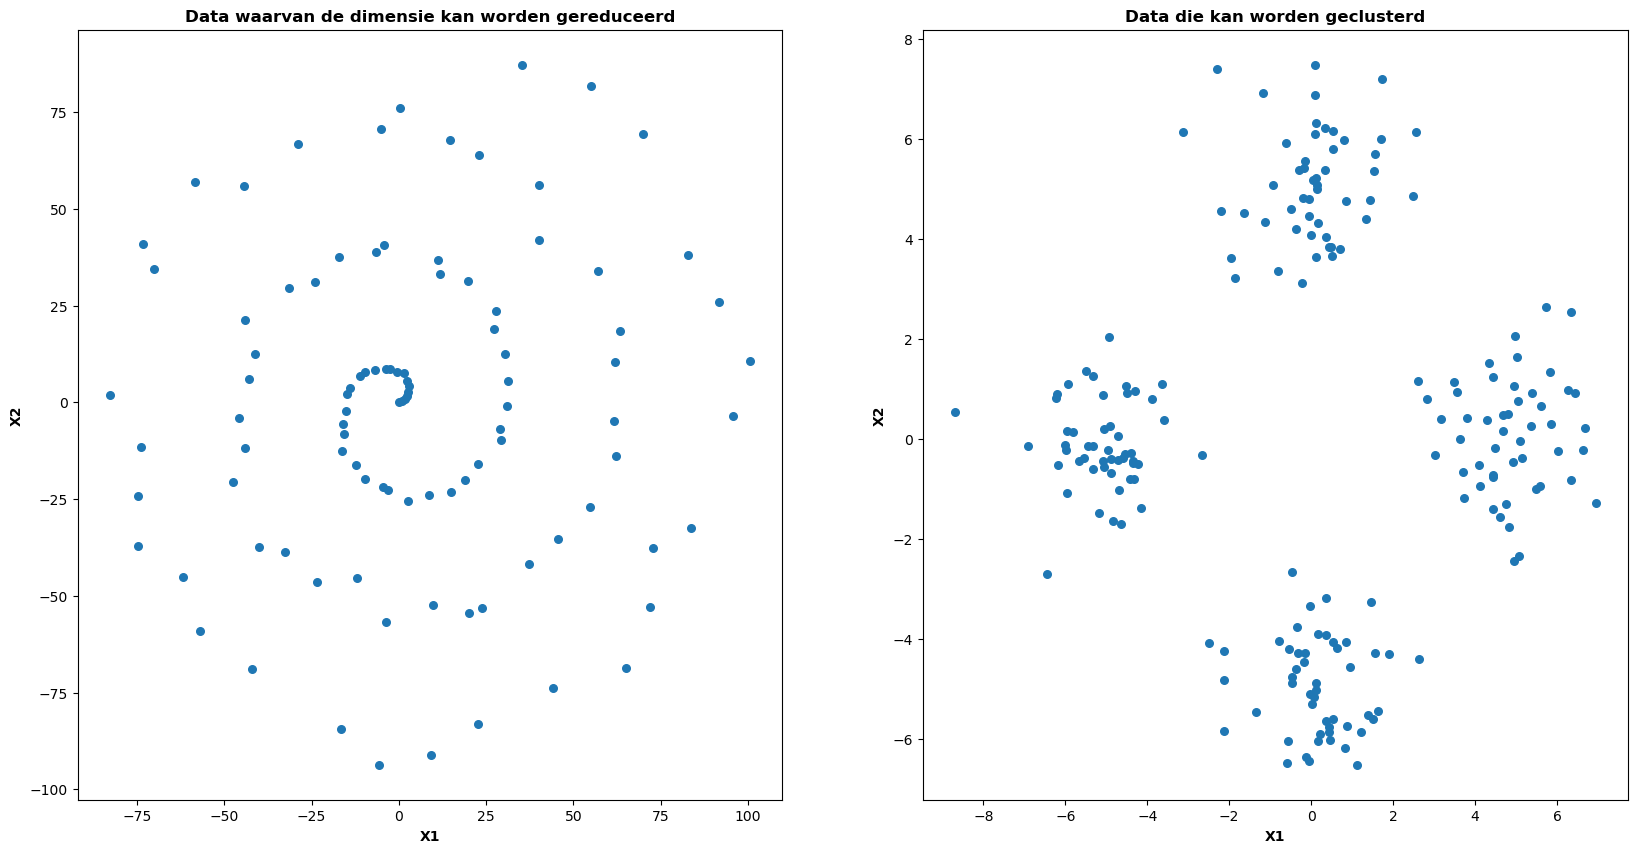

In [4]:
t = np.linspace(0,100,100)
X1 = np.cos(t/5)*t + np.random.normal(0,0.05,100)*t
X2 = np.sin(t/5)*t + np.random.normal(0,0.05,100)*t

plt.figure(figsize=(20,10))
plt.subplot(1,2,1)
plt.scatter(X1, X2, s=30)
plt.xlabel("X1",fontweight="bold")
plt.ylabel("X2",fontweight="bold")
plt.title("Data waarvan de dimensie kan worden gereduceerd",fontweight="bold")

X1, y1 = make_blobs(n_samples=100, centers=[[0, -5], [-5, 0]], random_state=6)
X2, y2 = make_blobs(n_samples=100, centers=[[0, 5], [5, 0]], random_state=8)

X = np.concatenate((X1,X2))

plt.subplot(1,2,2)
plt.scatter(X[:, 0], X[:, 1], s=30)
plt.xlabel("X1",fontweight="bold")
plt.ylabel("X2",fontweight="bold")
plt.title("Data die kan worden geclusterd",fontweight="bold")
plt.show()

### De unsupervised concepten, vervolg
We zijn op zoek naar plekken in de ruimte waar $P(X)$ relatief hoog is.

- **Dimensie-reductie**<br>
De plekken in de ruimte met een hogere kans op een waarneming suggereren een samenhang tussen de variabelen.<br>
De waarnemingen (of de kans op een waarneming) kan dan worden gezien als een functie over een kleinere verzameling van variabelen (de latente variabelen).
- **Clustering**<br>
De plekken in de ruimte met een hogere kans op een waarneming suggereren een combinatie van verschillende simpelere verdelingen. Deze simpelere verdelingen zouden kunnen horen bij bepaalde type waarnemingen. 

### Waarom dimensie-reductie?
Dimensie-reductie gaat ervan uit dat de 'werkelijke' dimensie van de data (latente variabelen) lager is dan de ruimte waarin het is gepresenteerd wordt.

- **Genereren van data**<br>
Wat zijn voorbeelden in de ruimte van voorbeelden die voor ons "echt" lijken?
- **Vereenvoudigen van modellen (rekentijd, overfitting, interpretatie)**<br>
Model met minder variabelen.
- **Visualiseren van data**<br>
Vinden van 'belangrijkste' dimensies om data te visualiseren.
- **curse of dimensionality**<br>
Niet-parametrische modellen die gebruikmaken van "dichtstbijzijnde punten" zullen minder goed werken.

### Curse of dimensionality
Zie opgave 4 van hoofdstuk 4 uit [ISL] voor een voorbeeld.

- Stel we hebben een kansvariabele $X$ die uniform verdeeld is op $[0,1]$. Hoeveel procent van de waarnemingen zal in het interval $[0.1,0.9]$ vallen?
- Stel dat we nu twee variabelen $X_1$ en $X_2$ hebben zo dat $(X_1, X_2)$ uniform verdeeld is op $[0,1] \times [0,1]$.<br>
Hoeveel procent van de waarnemingen zal in het vierkant $[0.1,0.9]\times[0.1,0.9]$ vallen?
- Stel dat we nu drie variabelen $X_1$, $X_2$ en $X_3$ hebben zo dat $(X_1, X_2, X_3)$ uniform verdeeld is op $[0,1]\times [0,1]\times [0,1]$.<br>
Hoeveel procent van de waarnemingen zal in de kubus $[0.1,0.9]\times[0.1,0.9]\times[0.1,0.9]$ vallen?
- Stel dat we nu $p$ variabelen $X_1, X_2, \ldots X_p$ hebben zo dat $(X_1, X_2, \ldots, X_p)$ uniform verdeeld is op $[0,1]\times [0,1]\times \ldots \times [0,1]$.<br>
Hoeveel procent van de waarnemingen zal in de hyperkubus $[0.1,0.9]\times \ldots\times[0.1,0.9]$ vallen?

### Curse of dimensionality, vervolg
Bij zeer veel variabelen zullen punten niet snel dichtbij elkaar staan. Als de ruimte van data zeer hoog dimensionaal is, zullen de meeste punten zich op de rand bevinden en zal de ruimte vrijwel leeg zijn (sparse).

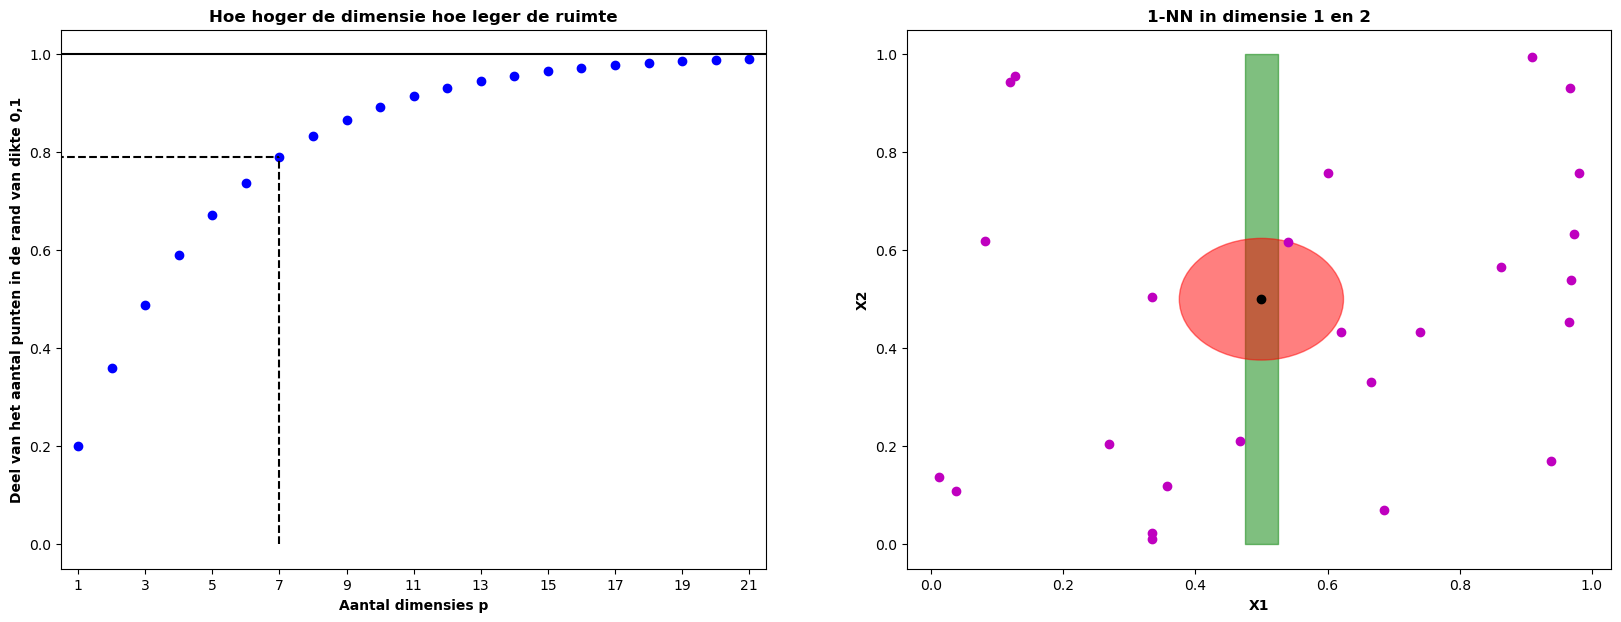

In [3]:
P = 22
dim = 7
p = np.arange(1, P)
x = np.arange(0, P+1)
r = 1-0.8**p
plt.figure(figsize=(20,7))
plt.subplot(1,2,1)
plt.xticks(np.arange(1, P,2))
plt.xlim(0.5,P-0.5)
plt.xlabel("Aantal dimensies p",fontweight="bold")
plt.ylabel("Deel van het aantal punten in de rand van dikte 0,1",fontweight="bold")
plt.title("Hoe hoger de dimensie hoe leger de ruimte",fontweight="bold")
plt.plot(p, r, 'bo')
plt.plot([0,p[dim-1]],[r[dim-1],r[dim-1]],'k--')
plt.plot([p[dim-1],p[dim-1]],[0,r[dim-1]],'k--')
plt.plot(x,np.ones(23),'k-')

N = 25
x1 = np.random.uniform(size=N)
x2 = np.random.uniform(size=N)
min1 = np.min(np.abs(x1-0.5))
min2 = math.sqrt(np.min((x1-0.5)**2+(x2-0.5)**2))
circle = plt.Circle((0.5, 0.5), min2, color='r', alpha=0.5)

axes = plt.subplot(1,2,2)
plt.xlabel("X1",fontweight="bold")
plt.ylabel("X2",fontweight="bold")
plt.title("1-NN in dimensie 1 en 2",fontweight="bold")
plt.plot(x1, x2, 'mo')
plt.plot(0.5,0.5,'ko')
X = np.linspace(0,1,100)
plt.fill_between(X, 0, 1, where= np.abs(X-0.5) < min1,
                color='green', alpha=0.5)
axes.add_artist(circle)
plt.show()


### Dimensie-reductie-methoden
- **Lineair**
     - Principal component analysis (PCA)
     - Random projection
     - ...
- **Manifold learning (niet-lineair)**
     - isometric mapping (Isomap)
     - locally linear embedding (LLE)
     - t-distributed stochastic neighbor embedding (t-SNE)
     - multidimensional scaling (MDS)
     - ...

### Principal component analysis

* Zie 12.2 uit [ISLP] en 20.1 uit [PML1]
* Zie [user guide](https://scikit-learn.org/stable/modules/decomposition.html#principal-component-analysis-pca) en [api](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html#pca) van scikit-learn
* Hier zullen we in het tweede gedeelte van dit blok op terugkomen.

In het kort:

- We gaan ervan uit dat de vorm van de puntenwolk te benaderen is als een hoog-dimensionale matras (lineair) die in de variabelen-ruimte ligt.
- In enkele dimensies is de matras lang, in andere dimensies is de matras dun.
- PCA detecteert de verschillende richtingen en de bijbehorende variantie (van de wolk)
- Vervolgens kan men de datawolk op een lager dimensionale ruimte projecteren.


### Random projection

* Zie [user guide](https://scikit-learn.org/stable/modules/random_projection.html) en [api](https://scikit-learn.org/stable/api/sklearn.random_projection.html) van scikit-learn
* Zie 15.6.4 in [PML1] voor een toepassing

In het kort:

- Dit is een projectie naar een lager dimensionale ruimte zonder eerst de wolk te bestuderen.
- De projectie maakt gebruik van willekeurig gekozen richtingen.
- Er is een stelling die zegt dat de afstanden tussen de punten met een grote waarschijnlijkheid (ongeveer) bewaard blijven (afhankelijk van het aantal waarnemingen en aantal dimensies in de lager dimensionale ruimte).
- Maakt gebruik van een foutmaat $\epsilon$. Hoe lager $\epsilon$ hoe beter de afstanden behouden blijven. Hoe lager $\epsilon$ hoe groter de inbeddingsruimte moet zijn.
- Als $k$ het aantal waarnemingen is; hoe groter $k$ hoe groter de inbeddingsruimte moet zijn.

### PCA versus random projection
PCA: *adaptieve dimensie-reductie*<br>
Eerst de data bestuderen en dan projecteren.

<br>

Random projection: *niet-adaptieve dimensie-reductie*<br>
Projectie zonder de data van tevoren te bestuderen

- Voordeel PCA: beter inzicht in de data
- Voordeel Random projection: bij veel variabelen praktischer

### Manifold learning
- De datawolk hoeft geen lineaire structuur in de ruimte te hebben.
- In dat geval kan men manifold learning gebruiken om de puntenwolk in te bedden in een lager dimensionale ruimte.
- Men probeert nog steeds afstanden te behouden.
- Dat kan over de hele ruimte, maar ook lokaal.

### isometric mapping (Isomap)

1. Bepaal voor elk punt de buren middels
    - afstand $\epsilon$ ($\epsilon$-isomap)
    - dichtstbijzijnde $K$ buren ($K$-isomap)  

  Afstand $d$ tussen deze buren is de "normale" afstand.<br>
  De afstand $d$ tussen punten die geen buren zijn zullen we op oneindig zetten.

2. Voor elke twee punten in de ruimte $k$ en $l$ definieren we de afstand als
$$
d_{\textrm{nieuw}} = \min_{j} \{d(k,l) , d(k,j) + d(j,l)\}
$$
3. Aan de hand van deze nieuwe afstanden maken we een inbedding op een lineaire manier

<br>

Zie [scikit-learn](https://scikit-learn.org/stable/modules/manifold.html#isomap) en referenties daarin (ook [hier](https://www.robots.ox.ac.uk/~az/lectures/ml/) te vinden).

### locally linear embedding (LLE)
1. Bepaal voor elk punt de $K$ buren
2. Beschrijf elk punt zo goed mogelijk in termen van zijn buren.<br>
Lineaire combinaties en *reconstruction error* (met enkele eisen op de gewichten) als kwadraatsom.
3. Vind de ingebedde vectoren zo dat elk ingebed punt op dezelfde wijze beschreven kan worden door zijn ingebedde buren.<br>
Opnieuw een kwadraatsom, maar nu om de inbedding te bepalen.

<br>

Zie [scikit-learn](https://scikit-learn.org/stable/modules/manifold.html#locally-linear-embedding) en referenties daarin (ook [hier](https://www.robots.ox.ac.uk/~az/lectures/ml/) te vinden).

###  t-distributed stochastic neighbor embedding (t-SNE)
- Geschikt voor het visualiseren van data in twee of drie dimensies.
- Geschikt in de situatie dat de latent space zelf uit verschillende groepen bestaat.

**stochastic neighbor embedding**<br>
Afstanden tussen punten worden geconverteerd naar voorwaardelijke kansen. Hoe dichter een punt $j$ bij punt $i$, hoe groter de kans $p(i|j)$.

Er wordt ook een kansverdeling (t-verdeling) gemaakt voor de latente ruimte. Het verschil tussen de verdelingen probeert men te minimaliseren (Kullback–Leibler divergence).

Nadeel: erg langzaam<br>
Zie [scikit-learn](https://scikit-learn.org/stable/modules/manifold.html#t-distributed-stochastic-neighbor-embedding-t-sne) en referenties daarin.

### Manifold learning, vervolg

* Zorg ervoor dat de data herschaald wordt.
* LLE werkt goed op kleine problemen
* IsoMap werk over het algemeen beter op hoog-dimensionale data
* t-SNE zeer geschikt als de data geclustered is, maar kan erg langzaam zijn.

Zie verder:

- [https://scikit-learn.org/stable/modules/manifold.html](https://scikit-learn.org/stable/modules/manifold.html)
- [https://scikit-learn.org/stable/auto_examples/manifold/plot_compare_methods.html#sphx-glr-auto-examples-manifold-plot-compare-methods-py](https://scikit-learn.org/stable/auto_examples/manifold/plot_compare_methods.html#sphx-glr-auto-examples-manifold-plot-compare-methods-py)
- [https://jakevdp.github.io/PythonDataScienceHandbook/05.10-manifold-learning.html](https://jakevdp.github.io/PythonDataScienceHandbook/05.10-manifold-learning.html)

voor een bespreking van verschillende algoritmes en voor- en nadelen.